# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Alice Miller, Emma Crawford, Nina Beadnell, Maciek Romanowski**

## Setup

In [1]:
# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay, 
    ConfusionMatrixDisplay, roc_auc_score, average_precision_score, accuracy_score, precision_score, 
    recall_score, f1_score, silhouette_score, silhouette_samples)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (AgglomerativeClustering, KMeans)
from scipy.cluster.hierarchy import (linkage, dendrogram, fcluster)
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

from IPython.display import Markdown

import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

In [2]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

This report investigates daily river water levels recorded at 392 monitoring stations across 35 counties in Scotland between 2014 and 2026. Using supervised and unsupervised machine learning techniques, we aim to identify meaningful patterns in river behaviour and investigate the potential for predicting flood events.

The data used in this report contains the river level monitoring stations (by name and by ID label), their geographical location (county of Scotland, as well as longitude and latitude) and the reported daily average, minimum and maximum water levels (in metres).

Two objectives are considered. First, clustering is used to group monitoring stations according to similarities in their water-level characteristics. Second, binary classification is used to predict whether a station will experience a flood based on observations from the preceding seven days.

Before modelling, we analyse the data for missing observations, outliers and differences in station coverage. Relevant features are then constructed to describe river properties and aid further analysis.

First, we consider clustering, an unsupervised machine learning task where, based on the constructed features, we try to group together stations with similar properties. Clustering is crucial in identifying trends, patterns and intrinsic relationships in the dataset. We implement the K-means++ and hierarchical clustering algorithms and compare their performance. We observe that all stations can be grouped into three separate groups: one containing all of the tidal stations, [input rest].

Second, we consider classification, a supervised machine learning task, where we aim to build a model to predict future flood events. We train and test various models to find the one with the best performance. Given that flood events are rare, we choose as a baseline a model which always predicts no flood. Our best performing model is [insert model].

Building on our classification model, we identify factors that can be used to predict flood events. These findings can help government agencies understand river behaviour and identify regions at high risk of flooding. By predicting floods before they occur, we aim to ease the strain on government and emergency services, and reduce the human cost of flooding [reference 1].

# Exploratory Data Analysis and Feature Engineering

##  Exploratory Data Analysis
- Missing values plot
- Report on 'abnormal values'
- Apply all findings via `data_prepare` function

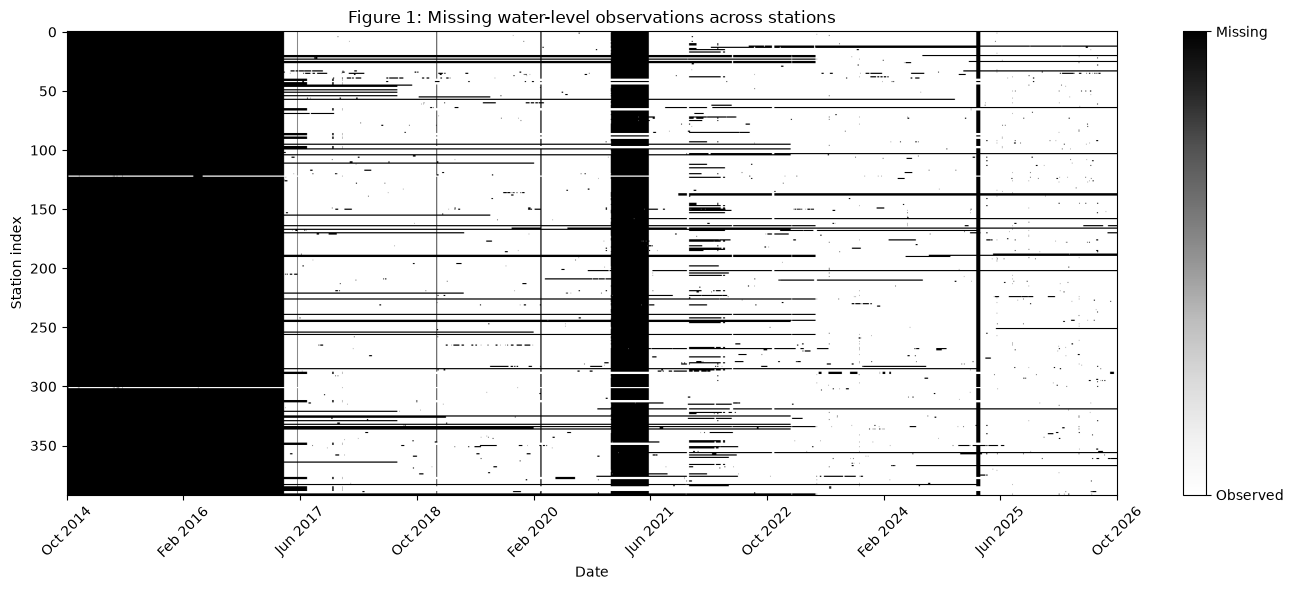

In [3]:
# Investigating the missing observations across different stations

# Select date columns
date_cols = df_avg.columns[3:]

data = df_avg[date_cols].apply(pd.to_numeric, errors="coerce")  # Make sure that the data has numerical values or NaN for missing values

# Convert columns to dates
data.columns = pd.to_datetime(date_cols, dayfirst=True)

# Insert missing dates
all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")

# If the date does NOT exist pandas creates a new column filled with NaN
data = data.reindex(columns=all_dates)

# Missing-data matrix: 1 = missing, 0 = observed
missing = data.isna().astype(int)

# Plot a heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(missing, aspect="auto", cmap="Greys")

# Date labels
ticks = np.linspace(0, len(all_dates) - 1, 10, dtype=int)

# Set labels, ticks, and title
ax.set_xticks(ticks)
ax.set_xticklabels(all_dates[ticks].strftime("%b %Y"), rotation=45)

ax.set_xlabel("Date")
ax.set_ylabel("Station index")
ax.set_title("Figure 1: Missing water-level observations across stations")

# Colourbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Observed", "Missing"])

plt.tight_layout()
plt.show()

In [4]:
results = []

for name, df in {
    "Average": df_avg,
    "Maximum": df_max,
    "Minimum": df_min
}.items():

    data = df.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

    n_outliers = (data.abs() > 30).sum().sum()
    n_observations = data.count().sum()

    results.append({
        "Dataset": name,
        "Observations": n_observations,
        "Abnormal observations": n_outliers,
        "Percentage (%)": 100 * n_outliers / n_observations
    })
    
display(Markdown("**Table 1: Summary of Abnormal Water-Level Observations Across Datasets**"))
display(pd.DataFrame(results).round(4).set_index("Dataset"))

# Frequency of abnormal values in the average dataset
data = df_avg.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

display(Markdown("**Table 2: Frequency of Abnormal Values in the Average River-Level Dataset**"))
display(
    data.where(data.abs() > 36).stack().value_counts()
    .rename_axis("Abnormal value")
    .to_frame("Frequency")
)

**Table 1: Summary of Abnormal Water-Level Observations Across Datasets**

,Observations,Abnormal observations,Percentage (%)
Dataset,,,
Average,1190691,929,0.0780
Maximum,1190691,979,0.0822
Minimum,1190691,759,0.0637


**Table 2: Frequency of Abnormal Values in the Average River-Level Dataset**

,Frequency
Abnormal value,
98.070,1
170.415,1
192.294,1
20833.839,1
20833.901,1
...,...
21740.183,1
11905.747,1
21979.385,1


In [5]:
# Data preprocessing
def data_prepare(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(pd.to_numeric, errors="coerce")

    # Replace observations with |value| > 36 with NaN
    data = data.mask(data.abs() > 36)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = data_prepare(df_avg)
minimum = data_prepare(df_min)
maximum = data_prepare(df_max)

## Clustering
The first step in building a model is to consider the features that will be used. We note that the clustering and classification tasks are significantly different and will therefore require different features to be considered. One of the main differences is that, while for clustering we use the entire dataset, for classification we use only the preceding seven days. It is therefore sensible to construct features based on the entire dataset for clustering, but features depending only on seven consecutive days for the classification task.

### Feature engineering for Clustering problem
In the datasets, we are given monitoring stations and their respective mean, maximum and minimum water levels. Since these values depend on the characteristics of a specific river and the reference elevation of the station, they are not particularly well suited to the clustering problem, so we look for other possible measures.

One such measure that immediately comes to mind is the variability of the water level at each station. The simplest way to quantify this is to look at the range of the data (i.e. max − min). However, this measure is easily skewed by outliers. As an example, we can think of a river that has experienced only one flood event throughout the observation period. Using the range as a feature might result in this river being clustered together with rivers that exhibit consistently large water-level fluctuations, which would not be a desirable assignment. A similar problem arises when using the standard deviation. For this reason, we believe that the interquartile range (IQR) is a suitable measure in this case, since it is resistant to outliers and provides a more reliable measure of typical water-level variability.

Given that mitigating the risk of flooding is one of our main interests, we might also want to consider how extreme unusually high water levels are, which could help us identify stations susceptible to flooding. Conversely, we might also want to consider how extreme unusually low water levels are when investigating potential droughts.

We might also want to consider within-day variability and the magnitude of day-to-day changes. On a longer timescale, we can consider the autocorrelation between observations to understand whether water-level fluctuations occur predominantly over short or long timescales. We know that different seasons are characterised by different amounts of rainfall, so seasonality might also play an important role. Finally, we might want to introduce a feature that measures unusually large within-day fluctuations to distinguish between rivers with consistently large daily fluctuations and those with occasional but extreme ones.

As the next step, we investigate the correlation between the features to potentially disregard those that are highly correlated, as including several features that convey similar information might disproportionately influence our clustering algorithm. We can see that all measures of autocorrelation are highly correlated, so we decide to retain only the weekly autocorrelation, which provides the most distinct information relative to the other features.

Let $h_i(t)$ denote the average water level at station $i$ on day $t$, with $h_i^{\max}(t)$ and $h_i^{\min}(t)$ denoting the corresponding maximum and minimum water levels. We additionally denote by $Q_{p,i}$ the $p$-quantile of the average water-level observations at station $i$. Based on the considerations above, we construct the following features for each station. Note that when constructing the upper- and lower-tail intensity features, we normalise the distance between the corresponding extreme quantile and the median by the interquartile range. This allows us to quantify how extreme these observations are relative to the typical variability of water levels at each station. For instance, a water-level increase of 1 m might be relatively common for one river but highly unusual for another. By normalising with respect to the IQR, we aim to capture this distinction.

| Feature | Mathematical definition | Motivation |
|---|---|---|
| Interquartile range (IQR) | $Q_{0.75,i}-Q_{0.25,i}$ | Typical water-level variability |
| Upper-tail intensity | $\frac{Q_{0.99,i}-Q_{0.50,i}}{\mathrm{IQR}_i}$ | Relative extremity of high water levels |
| Lower-tail intensity | $\frac{Q_{0.50,i}-Q_{0.01,i}}{\mathrm{IQR}_i}$ | Relative extremity of low water levels |
| Within-day variability | $\operatorname{median}_t(h_i^{\max}(t)-h_i^{\min}(t))$ | Typical daily water-level fluctuations |
| Daily changes | $\operatorname{median}_t\lvert h_i(t)-h_i(t-1)\rvert$ | Typical day-to-day changes |
| Autocorrelation | $\operatorname{Corr}(h_i(t),h_i(t-k))$ | Temporal persistence over $k$ days |
| Seasonal variation | $\operatorname{median}_{\text{Jan–Jun}}h_i-\operatorname{median}_{\text{Jul–Dec}}h_i$ | Seasonal differences |


In [6]:
# Define the features we want to use for the clustering problem 

# Interquartile range
iqr = avg.quantile(0.75) - avg.quantile(0.25)

# Upper-tail intensity
tail = ((avg.quantile(0.99) - avg.quantile(0.50)) / iqr.where(iqr > 1e-8))

# Lower-tail intensity
tail_l = ((avg.quantile(0.50) - avg.quantile(0.01)) / iqr.where(iqr > 1e-8))

# Within-day variability (where to account for possible NaN values)
daily_range = (maximum - minimum).where(maximum >= minimum)
R = daily_range.median()

# Daily changes
D = avg.diff().abs().median()

# Daily qutocorrelation
A1 = avg.corrwith(avg.shift(1))

# Seasonal variation
first_half = avg[avg.index.month.isin([1, 2, 3, 4, 5, 6])].median()
second_half = avg[avg.index.month.isin([7, 8, 9, 10, 11, 12])].median()

S = first_half - second_half

# Construct feature matrix
X_cluster = pd.DataFrame({
    "IQR": iqr,
    "Upper_tail": tail,
    "Daily_range": R,
    "Daily_change": D,
    "Autocorr_1": A1,
    "Seasonality": S,
    "Lower_tail": tail_l
})

### Clustering and Outcomes

During our analysis, we investigated two different clustering methods: K-means++ and hierarchical clustering. In clustering, we aim to minimise dissimilarity within clusters and maximise dissimilarity between different clusters. To assess how well this is achieved and determine an appropriate number of clusters, we investigate the silhouette score and within-cluster variation.

We found that both methods performed well in grouping together stations exhibiting tidal behaviour. While this was a very promising initial result, we also wanted to distinguish between different types of rivers with non-tidal observations. Hierarchical clustering yielded promising silhouette scores of above 0.6 for the three- and four-cluster solutions. However, upon further investigation, we found that this was achieved by constructing one disproportionately large cluster alongside several very small ones, which provided relatively little insight into the behaviour of most stations.

On the other hand, K-means++ achieved a considerably higher silhouette score for the two-cluster solution than for solutions with more clusters. While the elbow plot was not particularly insightful, the silhouette analysis clearly favoured the two-cluster solution. However, further investigation revealed that this solution primarily distinguishes between stations exhibiting tidal and non-tidal behaviour. Although this is an important finding and provides evidence that our clustering captures meaningful characteristics of the stations, given the relatively small number of tidal stations, we also wanted to explore different subcategories of non-tidal stations.

The three-cluster solution achieved a considerably low silhouette score of approximately 0.30, which was initially concerning. However, upon investigating the characteristics of the individual clusters, we found that they exhibited meaningfully different water-level behaviour. Considering the nature of the problem, there is no particular reason to expect Scottish rivers to fall into clearly separated categories. We therefore decided to proceed with the three-cluster K-means++ solution, which we believe provides a sensible compromise between statistical separation and physical interpretability. We also note that we standardise our features, since they are measured on different scales. Without standardisation, features with a larger numerical variability might disproportionately influence the distance between observations and hence the resulting clustering solution.

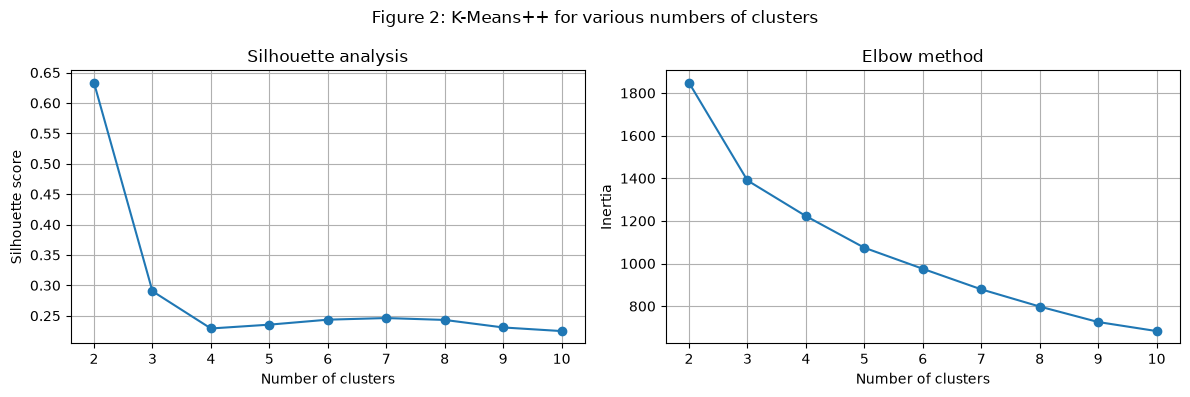

In [7]:
# Creating the pipeline and investigating the number of clusters

k_values = range(2, 11)

silhouette_scores = []
inertias = []

for k in k_values:

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        ))
    ])

    labels = pipeline.fit_predict(X_cluster)

    X_scaled = pipeline.named_steps["scaler"].transform(X_cluster)

    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

    inertias.append(
        pipeline.named_steps["kmeans"].inertia_
    )


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, silhouette_scores, marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Silhouette score")
axes[0].set_title("Silhouette analysis")

axes[1].plot(k_values, inertias, marker="o")
fig.suptitle("Figure 2: K-Means++ for various numbers of clusters")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Inertia")
axes[1].set_title("Elbow method")

for ax in axes:
    ax.grid()

plt.tight_layout()
plt.show()

In [8]:
# Building a model with 3 clusters
pipeline3 = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        random_state=42
    ))
])

labels3 = pipeline3.fit_predict(X_cluster)

X_clustered3 = X_cluster.copy()
X_clustered3["Cluster"] = labels3

The final clustering solution consists of three clusters. The smallest cluster, Cluster 1, contains 10 of the 12 identified tidal observation stations, along with 10 non-tidal stations. In this cluster, we observe the largest median upper- and lower-tail intensities, as well as by far the largest within-day variability. These characteristics are consistent with the presence of tidal observations. An interesting avenue for further investigation is to explore the non-tidal stations assigned to this cluster, whose large within-day fluctuations might be associated with sudden high-water events, unrecorded tidal influences, or other hydrological characteristics.

The two remaining clusters distinguish predominantly non-tidal stations, with the most pronounced differences in IQR, upper-tail intensity, and seasonality.

Cluster 0 corresponds to stations exhibiting almost no seasonal variation and a relatively low median IQR. These stations are also characterised by small within-day fluctuations and day-to-day changes. We can therefore describe this cluster as representing relatively stable rivers with low typical water-level variability.

Cluster 2, on the other hand, exhibits a considerably stronger seasonal dependence, with higher water levels generally observed during the second half of the year. This is particularly interesting as it is consistent with seasonal rainfall patterns observed in parts of Scotland [[4]](#ref4). It is also characterised by a median IQR approximately twice as large as that of Cluster 0, alongside larger within-day fluctuations and day-to-day changes. We can therefore describe these rivers as naturally more variable and exhibiting more pronounced seasonal variations.

Interestingly, by comparing the upper-tail intensities, we find that the more stable rivers experience more extreme high-water events relative to their typical variability than the naturally more variable rivers. We might hypothesise that flood events represent a larger departure from the typical behaviour of stable rivers. In contrast, extreme observations in more variable rivers may be partly attributable to their naturally larger fluctuations. Further investigation is needed to determine whether these differences translate into differences in flood susceptibility.

Although our final clustering solution achieves a relatively low silhouette score of approximately 0.30, we believe that the identified clusters provide a meaningful interpretation of the data. The relatively weak separation may suggest that Scottish rivers vary continuously rather than falling into clearly defined categories. We should therefore interpret these clusters as groups of stations with broadly similar water-level behaviour, rather than as three fundamentally distinct river types.

From a river management perspective, our results suggest that different groups of monitoring stations might benefit from different monitoring strategies. For relatively stable rivers, unusually large departures from typical water levels might warrant particular attention. In contrast, for naturally more variable rivers, consider seasonal fluctuations when assessing exceptionally high water levels. Additionally, stations exhibiting tidal-like behaviour might benefit from more frequent monitoring to account for their considerably larger within-day fluctuations.

In [9]:
# Cluster sizes and median feature values
summary = X_clustered3.groupby("Cluster").median().round(3)
summary.insert(0, "Stations", X_clustered3.groupby("Cluster").size())

display(Markdown("**Table 3: Summary Statistics of Different Cluster Sizes**"))
display(summary)

# Identify tidal stations
results = df_avg.loc[X_clustered3.index, ["Observation_ID"]].copy()

results["Cluster"] = X_clustered3["Cluster"]

results["Tidal"] = results["Observation_ID"].str.contains(
    "tidal-level", case=False, na=False
)

display(Markdown("**Table 4: Distribution of Tidal vs. Non-Tidal Stations Across Clusters**"))
display(pd.crosstab(results["Cluster"], results["Tidal"]))

**Table 3: Summary Statistics of Different Cluster Sizes**

,Stations,IQR,Upper_tail,Daily_range,Daily_change,Autocorr_1,Seasonality,Lower_tail
Cluster,,,,,,,,
0,224,0.186,3.433,0.025,0.016,0.834,-0.003,0.860
1,20,0.292,4.016,2.874,0.107,0.531,-0.064,3.962
2,148,0.365,2.683,0.069,0.043,0.824,-0.064,0.864


**Table 4: Distribution of Tidal vs. Non-Tidal Stations Across Clusters**

Tidal,False,True
Cluster,,
0,224,0
1,10,10
2,146,2


## Feature engineering for Classification problem
Development of a classification model to predict if a flood event might happen on any given day, considering the previous 7 days of water levels, requires consideration of appropriate features.

A preliminary task required identification of all valid periods in the data in which 7 consecutive days and the proceeding next day were available (that is, containing no missing data across a whole 8-day period). This identification was considered over each data set, daily average, minimum and maximum water levels, and found 1166162 suitable cases of these valid 8-days. 

In constructing a suitable test and train selection of the data, a common 80% test and 20% train split was chosen. Due to a large number of suitable valid 8-days, this split was deemed satisfactory. The nature of our data captures time related dependencies such as weather patterns and seasonality. A random selection of valid 8-day windows across the data to use as test and training, would lead to potential data leakage due to a lack of consideration of these time related patterns. Opting instead for a cumulative count of valid windows providing a chronological assignment of test and train was chosen. The earliest 80% of periods used in the training set (932957 samples) whilst the final 20% in the test set (233205 samples). 

Response variable, labeling an event as flood or not flood, was not given in the data set requiring an external determination of this labeling. In this report, classification of a flood event is deemed as an observation exceeding the 99th percentile of the maximum water levels in the training dataset for each station (from the training set to avoid data leakage). For each station $i$, we therefore define a threshold $q_i$ as the 99th percentile of its maximum water-level observations in the training dataset. The classification label for station $i$ on day $t$ is then defined as 
$$
y_i(t)=
\begin{cases}
1, & h_i^{\max}(t)>q_i,\\
0, & h_i^{\max}(t)\leq q_i.
\end{cases}
$$
When applied across all data, reported 1.02% flood rate in training and 1.11% in testing.

The selected features, days 1 to 7 prior to the flood or not flood event, may vary substantially across all valid 8-days. For instance, a rapid water level increase in day 7 may be obscured by unassuming levels in days 1 to 6, if features are left untransformed there is a potential to miss flood events like this. Transformation of the features was applied through per-station Z-score standardisation to the daily maximum levels. This transformation is implemented by first subtracting each station's training set average from its daily water level and then dividing by its training set standard deviation. Transformation results in a measure of how many standard deviations a river sits above or below its own normal level.

Selected features, and appropriate transformations discussed were deemed most suitable for the proposed classification model. However, additional features extracted from the 7-day periods were considered such as mean, last day, maximum across all 7 days, range, standard deviation and last day squared. However models performance based on these alternative features, presented no improvements from the days 1 to 7 features. 


In [10]:
# Keep only 8-day windows where avg, min, and max all have no missing values
valid = avg.notna() & minimum.notna() & maximum.notna()
valid_8 = valid.rolling(8, min_periods=8).sum().eq(8)

# Find the date where 80% of valid windows have occurred (chronological 80/20 split)
total_valid = valid_8.sum().sum()
split = (valid_8.sum(axis=1).cumsum() >= 0.8 * total_valid).argmax() + 1

# Define floods as > 99th percentile of max water level
thresholds = maximum.iloc[:split].quantile(0.99).dropna()
flood = maximum[thresholds.index] > thresholds
valid_flood = flood.where(valid_8[thresholds.index])

y_train = valid_flood.iloc[:split].stack().dropna().astype(int)
y_test = valid_flood.iloc[split:].stack().dropna().astype(int)

# Standardise each station (Z-Score)
feat_source = maximum[thresholds.index]
station_mean = feat_source.iloc[:split].mean()
station_std = feat_source.iloc[:split].std().fillna(0) + 1e-8
feat_z = (feat_source - station_mean) / station_std

X_train_z = pd.DataFrame()
X_test_z = pd.DataFrame()

mask = valid_8[thresholds.index]

# Makes 7 separate columns: Day 1 (7 days ago) ... Day 7 (yesterday)
for i in range(1, 8):
    lag = 8 - i  # Day 1 is 7 days ago (lag=7), Day 7 is yesterday (lag=1)
    shifted = feat_z.shift(lag).where(mask)
    
    X_train_z[f"Day {i}"] = shifted.iloc[:split].stack().dropna()
    X_test_z[f"Day {i}"] = shifted.iloc[split:].stack().dropna()

# Summary table of the train-test split
y_all = pd.concat([y_train, y_test])
split_summary = pd.DataFrame({
    "Valid 8-Day Windows": [len(y_train), len(y_test), len(y_all)],
    "Share (%)": [100 * len(y_train) / total_valid, 100 * len(y_test) / total_valid, 100.0],
    "Flood Events": [int(y_train.sum()), int(y_test.sum()), int(y_all.sum())],
    "Flood Rate (%)": [100 * y_train.mean(), 100 * y_test.mean(), 100 * y_all.mean()]
}, index=["Training", "Test", "Total"])

display(Markdown("**Table 5: Flood events and Valid 8-day Intervals Across the Test Train Split**"))
display(split_summary.round(2))

**Table 5: Flood events and Valid 8-day Intervals Across the Test Train Split**

,Valid 8-Day Windows,Share (%),Flood Events,Flood Rate (%)
Training,932957,80.0,9535,1.02
Test,233205,20.0,2584,1.11
Total,1166162,100.0,12119,1.04


# Model Fitting and Tuning

Our objective is to predict whether a station will flood on Day 8 using water levels from the previous seven days (Days 1–7).As established during feature engineering (Table 5), flood events occur on only 1.04% of valid 8-day windows, making this an imbalanced binary classification problem. Because non flood days make up nearly 99% of the dataset, looking at the classification accuracy can be misleading. A trivial classifier that never predicts a flood still achieves 98.89% accuracy while catching zero floods. 

We therefore focus on recall, which measures the proportion of actual floods correctly identified, and precision, which measures the proportion of predicted floods that actually occur. We also consider the F1-score, which balances these two metrics, alongside ROC-AUC and Average Precision (AP), which assess the model's ability to distinguish between flood and non-flood events across different classification thresholds.

Our chosen approach uses a calibrated linear Support Vector Classifier (LinearSVC) fitted to the standardised daily maximum water levels. We tune the regularisation parameter $C$ using chronological cross-validation before selecting probability thresholds on a validation set. Finally, we evaluate the model on the unseen test set against a baseline that predicts flooding based on the previous day's flood status.

## Classification
### Baseline Model
We start the classification model by designing a baseline model to which we can compare our final model. Given that the data is highly imbalanced and flood events occur very rarely, a natural choice for a baseline model is a dummy classifier that always predicts no flood. Such a model will have incredible accuracy, but at a cost of 0 precision, recall and f1-score. This does not provide significant insight, so we instead choose as baseline a model that predicts whether a flood will happen or not only based on the previous day's max water level.


In [11]:
# Baseline model 
baseline = flood.shift(1).where(valid_8[thresholds.index])

y_pred_train_b = baseline.stack().loc[y_train.index].astype(int)
y_pred_test_b = baseline.stack().loc[y_test.index].astype(int)

results = []

for name, y_true, y_pred in [
    ("Train", y_train, y_pred_train_b),
    ("Test", y_test, y_pred_test_b)
]:
    results.append({
        "Dataset": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred)
    })
    
display(Markdown("**Table 6: Metrics for Baseline Model**"))
display(pd.DataFrame(results).set_index("Dataset").round(4))

**Table 6: Metrics for Baseline Model**

,Accuracy,Precision,Recall,F1-score
Dataset,,,,
Train,0.9861,0.3201,0.320,0.3200
Test,0.9882,0.4680,0.469,0.4685


We can see that this baseline model provides a very good accuracy score meaning that most events are correctly classified. Furthemore we see that precision and recall have essentially the same values, and our model only captures between 32% and 47% of floods that happen. We will use this baseline to compare to our final fitted model, so that we can examine how added complexity affects the predicting accuracy.

### Selected Classification Model

To classify next-day flood events, we use a linear Support Vector Classifier (LinearSVC). Figure 3 illustrates the relationship between standardised maximum water levels on Days 6 and 7 for a sample of 700 flood and 700 non-flood observations from the training set. Although flood events tend to be associated with higher water levels, there is substantial overlap between the two classes. A soft-margin classifier is therefore appropriate, as it allows some observations to violate the margin or be misclassified in order to obtain a more robust decision boundary.

LinearSVC was selected over the standard SVC implementation due to its computational efficiency, given the size of our training dataset (approximately 933,000 observations). Furthermore, the coefficients of the linear model allow us to investigate the relative contribution of water levels on each of the preceding seven days to flood predictions.

During initial exploration, we considered non-linear RBF support vector machines, over-sampling and under-sampling techniques, raw water levels and alternative seven-day summary features. We ultimately selected LinearSVC fitted to the seven standardised daily maximum water levels, retaining the original class distribution.

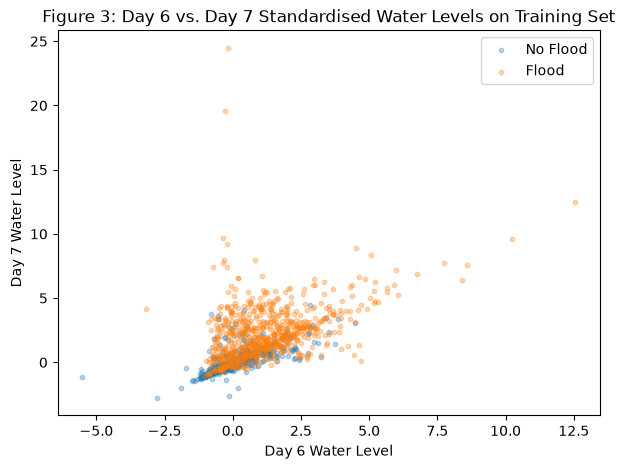

In [12]:
### REMOE IF TOO LONG ###
# Sample 700 non-flood days and 700 flood days from training
no_flood_sample = X_train_z[y_train == 0].sample(700, random_state=1)
flood_sample = X_train_z[y_train == 1].sample(700, random_state=1)

plt.figure(figsize=(7, 5))
plt.scatter(no_flood_sample["Day 6"], no_flood_sample["Day 7"], alpha=0.3, s=10, label="No Flood")
plt.scatter(flood_sample["Day 6"], flood_sample["Day 7"], alpha=0.3, s=10, label="Flood")
plt.xlabel("Day 6 Water Level")
plt.ylabel("Day 7 Water Level")
plt.title("Figure 3: Day 6 vs. Day 7 Standardised Water Levels on Training Set")
plt.legend()
plt.show()

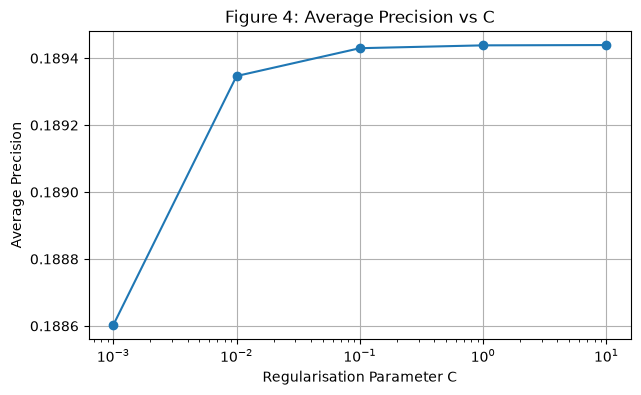

In [13]:
# Tune C using chronological 3-fold cross-validation
tscv = TimeSeriesSplit(n_splits=3)
C_values = [0.001, 0.01, 0.1, 1.0, 10.0]
mean_ap_scores = []

for c in C_values:
    svc = LinearSVC(C=c, random_state=1, max_iter=5000)
    scores = cross_val_score(svc, X_train_z, y_train, cv=tscv, scoring="average_precision")
    mean_ap_scores.append(scores.mean())

plt.figure(figsize=(7, 4))
plt.plot(C_values, mean_ap_scores, marker="o")
plt.xscale("log")
plt.xlabel("Regularisation Parameter C")
plt.ylabel("Average Precision")
plt.title("Figure 4: Average Precision vs C")
plt.grid(True)
plt.show()

The regularisation parameter C controls the trade-off between having a wide margin and correctly classifying the training data. A smaller value of C places less penalty on observations that violate the margin, allowing for a wider margin and reducing the risk of overfitting. A larger value of C places a greater penalty on margin violations, resulting in a narrower margin and a model that fits the training data more closely.

We tune C over the values ${0.001, 0.01, 0.1, 1, 10}$ using three-fold chronological cross-validation. This ensures that the model is trained on earlier observations and validated on later observations. Average Precision (AP) is used to assess performance due to the large class imbalance. Figure 4 shows that AP initially increases with C before levelling off at around C$=0.1$. We therefore select C$=0.1$, as larger values provide little improvement in performance whilst increasing the risk of overfitting.

Unlike logistic regression, LinearSVC does not directly estimate the probability of an observation belonging to a particular class. Instead, it produces a decision score based on the position of the observation relative to the decision boundary. We use Platt scaling to convert these scores into estimated flood probabilities by fitting a sigmoid function using three-fold cross-validation.

This allows us to adjust the probability threshold at which an observation is classified as a flood. Given the large class imbalance and the potential consequences of failing to predict a flood, the default threshold of 0.5 may not be appropriate. We therefore use the final 20% of the training data as a validation set to investigate how different thresholds affect precision, recall and F1-score.

**Table 7: Metrics for Different Thresholds**

,Threshold,Recall,Precision,F1-Score,Floods Predicted
0,0.01,0.7603,0.0694,0.1272,33136
1,0.02,0.5992,0.1213,0.2017,14942
2,0.09,0.3310,0.3516,0.3410,2847
3,0.50,0.0678,0.6156,0.1221,333


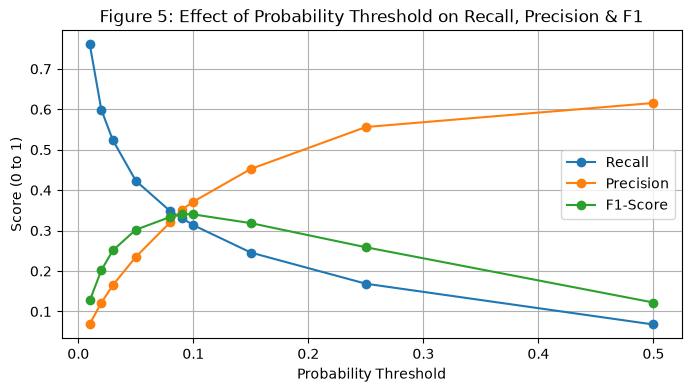

In [14]:
# Validation on 20% of training data
val_cut = int(0.8 * len(X_train_z))
X_tr, y_tr = X_train_z.iloc[:val_cut], y_train.iloc[:val_cut]
X_val, y_val = X_train_z.iloc[val_cut:], y_train.iloc[val_cut:]

# Fit LinearSVC (C=0.1) with Platt scaling
val_svc = CalibratedClassifierCV(
    LinearSVC(C=0.1, random_state=1, max_iter=5000),
    method="sigmoid",
    cv=3,
    ensemble=False
)
val_svc.fit(X_tr, y_tr)
val_probs = val_svc.predict_proba(X_val)[:, 1]

# Test different probability thresholds on the validation set
test_thresholds = [0.01, 0.02, 0.03, 0.05, 0.08, 0.09, 0.10, 0.15, 0.25, 0.50]
rows = []

for t in test_thresholds:
    preds = (val_probs >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Recall": recall_score(y_val, preds),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "F1-Score": f1_score(y_val, preds),
        "Floods Predicted": int(preds.sum())
    })

thresh_df = pd.DataFrame(rows)

# Display lowest, High-Recall, Balanced, and default thresholds
display(Markdown("**Table 7: Metrics for Different Thresholds**"))
display(thresh_df.iloc[[0, 1, 5, 9]].reset_index(drop=True).round(4))

# Plot Recall, Precision, and F1 for each threshold
plt.figure(figsize=(8, 4))
plt.plot(thresh_df["Threshold"], thresh_df["Recall"], marker="o", label="Recall")
plt.plot(thresh_df["Threshold"], thresh_df["Precision"], marker="o", label="Precision")
plt.plot(thresh_df["Threshold"], thresh_df["F1-Score"], marker="o", label="F1-Score")
plt.xlabel("Probability Threshold")
plt.ylabel("Score (0 to 1)")
plt.title("Figure 5: Effect of Probability Threshold on Recall, Precision & F1")
plt.legend()
plt.grid(True)
plt.show()

As shown in Table 7 and Figure 5, the default threshold of 0.5 identifies only 6.78% of actual flood events. Lowering the threshold increases recall but reduces precision, as more observations are classified as floods.

We selected two probability thresholds to reflect different government objectives. The first threshold of 0.02 achieves a recall of approximately 60% on the validation set, prioritising the detection of flood events where the consequences of missing a flood may outweigh the costs of a false alarm. The second threshold of 0.09 approximately maximises the F1-score, providing a better balance between precision and recall.

Both thresholds are selected using the validation set before evaluating their performance on the unseen test set.

In [15]:
# Refit the final calibrated model on all training data
final_svc = CalibratedClassifierCV(
    LinearSVC(C=0.1, random_state=1, max_iter=5000),
    method="sigmoid",
    cv=3,
    ensemble=False
)
final_svc.fit(X_train_z, y_train)

# Predict flood probabilities on the test set
y_probs = final_svc.predict_proba(X_test_z)[:, 1]

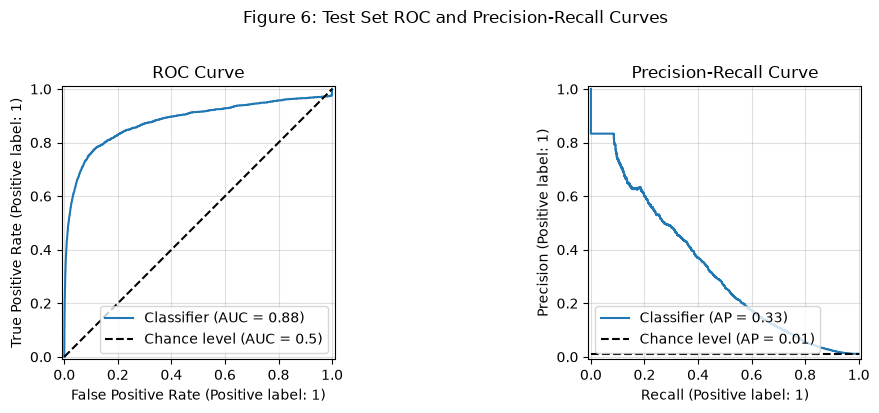

In [16]:
# Plot ROC Curve and Precision-Recall Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_test, y_probs, plot_chance_level=True, ax=axes[0])
axes[0].set_title("ROC Curve")
axes[0].grid(True, alpha=0.4)

PrecisionRecallDisplay.from_predictions(y_test, y_probs, plot_chance_level=True, ax=axes[1])
axes[1].set_title("Precision-Recall Curve")
axes[1].grid(True, alpha=0.4)

fig.suptitle("Figure 6: Test Set ROC and Precision-Recall Curves", y=1.02)
plt.tight_layout()
plt.show()

Having selected the regularisation parameter and probability thresholds, we refit the calibrated LinearSVC on the full training dataset and evaluate its performance on the test set.

Figure 6 shows the ROC and Precision-Recall curves, which assess the model's performance across different probability thresholds. The model achieves a ROC-AUC of 0.8804, suggesting it is able to distinguish well between flood and non-flood observations. However, given the large class imbalance, the Precision-Recall curve is particularly informative. The model achieves an Average Precision of 0.3251,which is much higher than the test set flood rate of 0.0111. This suggests that the model is able to identify observations with a higher risk of flooding, but there is still a trade-off between precision and recall.

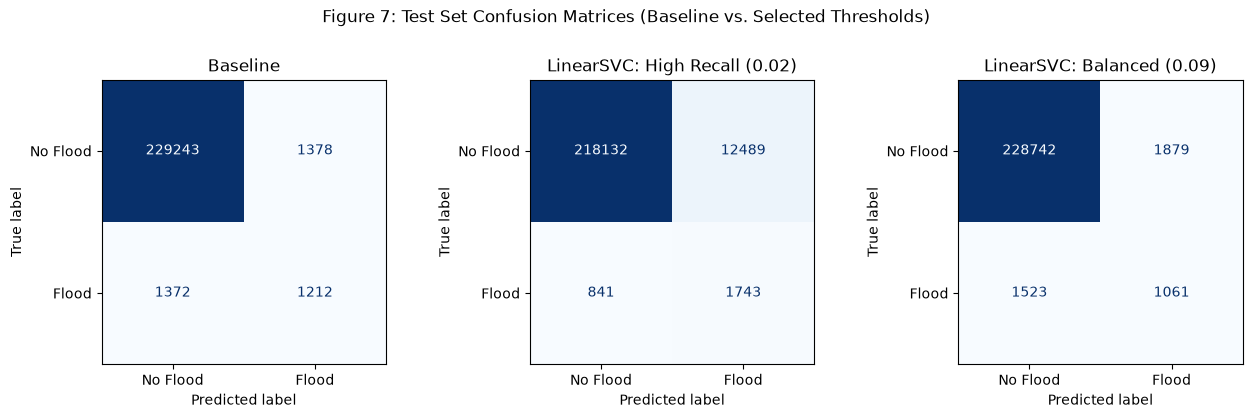

In [17]:
# Plot Test Set Confusion Matrices: Baseline vs. Selected Thresholds
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_b,
    display_labels=["No Flood", "Flood"], cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Baseline")

ConfusionMatrixDisplay.from_predictions(
    y_test, (y_probs >= 0.02).astype(int),
    display_labels=["No Flood", "Flood"], cmap="Blues", colorbar=False, ax=axes[1]
)
axes[1].set_title("LinearSVC: High Recall (0.02)")

ConfusionMatrixDisplay.from_predictions(
    y_test, (y_probs >= 0.09).astype(int),
    display_labels=["No Flood", "Flood"], cmap="Blues", colorbar=False, ax=axes[2]
)
axes[2].set_title("LinearSVC: Balanced (0.09)")

fig.suptitle("Figure 7: Test Set Confusion Matrices (Baseline vs. Selected Thresholds)", y=1.02)
plt.tight_layout()
plt.show()

In [18]:
# Compare Baseline vs chosen LinearSVC thresholds on the test set
models = {
    "Baseline": y_pred_test_b,
    "LinearSVC (0.02)": (y_probs >= 0.02).astype(int),
    "LinearSVC (0.09)": (y_probs >= 0.09).astype(int)
}

rows = []
for name, preds in models.items():
    rows.append({
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

test_df = pd.DataFrame(rows, index=models.keys())
display(Markdown("**Table 8: Metrics for Chosen Thresholds and Baseline Model**"))
display(test_df.round(4))

**Table 8: Metrics for Chosen Thresholds and Baseline Model**

,Accuracy,Precision,Recall,F1-Score
Baseline,0.9882,0.4680,0.4690,0.4685
LinearSVC (0.02),0.9428,0.1225,0.6745,0.2073
LinearSVC (0.09),0.9854,0.3609,0.4106,0.3841


Figure 7 and Table 8 compare the performance of the two selected thresholds against the baseline model on the test set.

At a threshold of 0.02, the LinearSVC correctly identifies 1,743 flood events compared to 1,212 for the baseline, increasing recall from 46.90% to 67.45%. However, the number of false positives increases from 1,378 to 12,489, reducing precision from 46.80% to 12.25%.

At a threshold of 0.09, the number of false positives is considerably lower at 1,879, but the number of missed flood events increases to 1,523. Although this threshold provides a better balance between precision and recall than the lower threshold, the baseline produces fewer false positives and false negatives and outperforms it across all four metrics.

Given our aim of achieving high recall whilst also considering precision, we select the LinearSVC at a threshold of 0.02 and the baseline model. The LinearSVC identifies the greatest proportion of flood events, whilst the baseline provides a better balance between recall and precision. Together, these models could support different levels of flood warnings.

# Interpretation, Discussion & Conclusions

- What Drives Flood Predictions (Feature Interpretation)
- Practicalities
- Limitations 


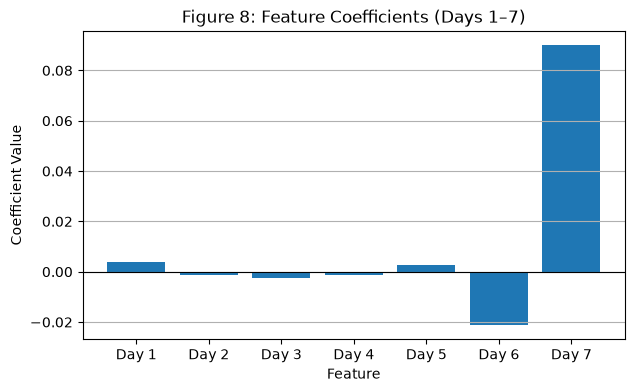

In [19]:
# Plot the 7 Feature Coefficients (matching Week 7 Workshop Exercise 10b)
weights = final_svc.calibrated_classifiers_[0].estimator.coef_[0]
coef_df = pd.DataFrame({"Day": X_train_z.columns, "Coefficient": weights})

plt.figure(figsize=(7, 4))
plt.bar(coef_df["Day"], coef_df["Coefficient"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Figure 8: Feature Coefficients (Days 1–7)")
plt.xlabel("Feature")
plt.ylabel("Coefficient Value")
plt.grid(axis="y")
plt.show()

# Generative AI statement

Generative AI was used in this project in following ways:
- Told us how to make citable references in Jupyter Notebook
- Debug code and help with error messages
- Suggest code improvements, and ways to make it cleaner and faster
- Improve the presentation of the plots 
- Turn the code outputs into neat tables 

# References

<a id="ref1"></a>
[1] Scottish Government (2026). 
*National Flood Resilience Strategy: Implementation Plan*.
[Available online](https://www.gov.scot/publications/national-flood-resilience-strategy-implementation-plan/pages/2/).

<a id="ref2"></a>
[2] Sell, T. (2026). *Machine Learning in Python: 
Week 1 – Introduction to Machine Learning and Feature Engineering*. 
Lecture notes, School of Mathematics, University of Edinburgh.

<a id="ref3"></a>
[3] pandas development team (n.d.). 
*Time series / date functionality*. pandas documentation.
[Available online](https://pandas.pydata.org/docs/user_guide/timeseries.html).
(Accessed: 24 November 2026).

<a id="ref4"></a>
[4] Met Office (n.d.). *Charterhall: Location-specific long-term 
averages (1991–2020)*. 
[Available online](https://www.metoffice.gov.uk/research/climate/maps-and-data/location-specific-long-term-averages/gcykcv8b2).
(Accessed: 25 November 2026).

[1] - https://audit.scot/uploads/2025-08/nr_250828_flooding_in_communities.pdf, ISBN 978 1 915839 80 0, AGS/2025/6

In [1]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Support files will be in project_files\
[NbConvertApp] Making directory .\project_files
[NbConvertApp] Writing 123865 bytes to notebook.tex
[NbConvertApp] Building PDF
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\ninab\anaconda3\envs\MLP_Group_Project\Scripts\jupyter-nbconvert.EXE\__main__.py", line 5, in <module>
  File "C:\Users\ninab\anaconda3\envs\MLP_Group_Project\Lib\site-packages\jupyter_core\application.py", line 284, in launch_instance
    super().launch_instance(argv=argv, **kwargs)
  File "C:\Users\ninab\anaconda3\envs\MLP_Group_Project\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "C:\Users\ninab\anaconda3\envs\MLP_Group_Project\Lib\site-packages\nbconvert\nbconvertapp.py", line 420, in start
    self.convert_notebooks()
  File "C:\User